# Results figures for the paper

The figures of Section 5 that are not already made by `fit/kalshi_fit.ipynb`, `fit/polymarket_fit.ipynb` and
`fit/midterm_comparison.ipynb`, and the exploratory numbers the section quotes:
1. the 2,000 resampled midterm stretches behind the pre-registered test;
2. Kalshi's and Polymarket's midterm results split into races on both platforms and races on one only;
3. where the midterm upsets fell, state by state;
4. checks on the training primaries: runoff states and how long markets took to settle;
5. p-values for the level and persistence questions, naive and allowing for states.

Everything here is exploratory except panel 1, which redraws the pre-registered test itself and must reproduce its
interval exactly.

In [1]:
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

sys.path.insert(0, "../fit")
import midterm_test
import stretch

FIGURES, TABLES = Path("figures"), Path("tables")
FIGURES.mkdir(exist_ok=True)
TABLES.mkdir(exist_ok=True)
STAGE = "final" if Path("../fit/results/midterm_test_final.csv").exists() else "preliminary"
TEST = pd.read_csv(f"../fit/results/midterm_test_{STAGE}.csv").set_index("platform")
PLATFORMS = ["Kalshi", "Polymarket"]

GENERAL, PRIMARY, MIDTERMS = "#2a78d6", "#eb6834", "#1baf7a"
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
EMPTY_TILE = "#f0efec"
DIVERGING = LinearSegmentedColormap.from_list(
    "fewer_more", ["#184f95", "#6da7ec", "#e8e7e3", "#f3a07a", "#c4471c"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "figure.dpi": 110, "text.parse_math": False,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")


def value_grid(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def show(value):
    return "no limit" if np.isposinf(value) else f"{value:.2f}"


test = {p: midterm_test.night(p, midterm_test.TEST_DAY, midterm_test.TEST_SNAPSHOT, midterm_test.RUNOFF_STATES)[0]
        for p in PLATFORMS}
race = pd.read_csv(midterm_test.ELIGIBLE, dtype={"contest_id": str})[["platform", "contest_id", "race"]]
for p in PLATFORMS:
    test[p] = test[p].merge(race, on=["platform", "contest_id"], how="left").reset_index(drop=True)
    assert test[p]["race"].notna().all()
    assert np.isclose(stretch.fit(test[p]["log_odds"], test[p]["won"]), TEST.loc[p, "b"])
{p: len(t) for p, t in test.items()}

{'Kalshi': 187, 'Polymarket': 145}

## 1. The pre-registered test, drawn

The 2,000 stretches refitted on resampled states, the same resamples as `fit/midterm_test.py`. The darker bars are the
central 95%, which is the test's interval. The grey line marks a calibrated market and the dashed blue line the frozen
2024 value.

,platform,stretch,low,high,share above 1,share at or below 1,share above 2024 value
0,Kalshi,1.319,0.876,2.353,0.921,0.079,0.098
1,Polymarket,1.664,1.211,2.913,0.998,0.002,0.354


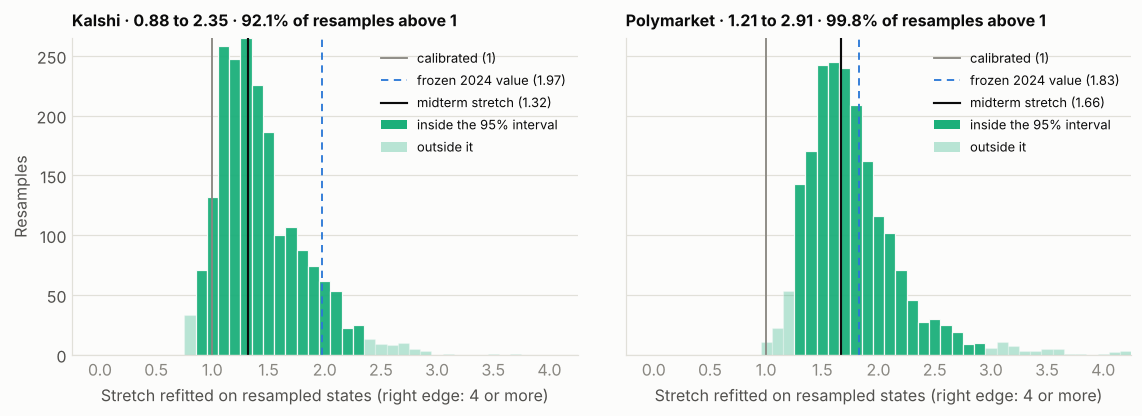

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
LEFT, RIGHT = -0.25, 4.25
bins = np.linspace(LEFT, RIGHT, 46)
resample_rows = []
for ax, p in zip(axes, PLATFORMS):
    draws = stretch.bootstrap(test[p], "state")["All"].to_numpy()
    low, high = stretch.interval(draws)
    assert np.isclose(low, TEST.loc[p, "low"]) and np.isclose(high, TEST.loc[p, "high"])
    b = TEST.loc[p, "b"]
    counts, edges = np.histogram(np.clip(draws, LEFT, RIGHT - 1e-9), bins)
    inside = (edges[:-1] + edges[1:]) / 2
    inside = (inside >= low) & (inside <= high)
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge", color=MIDTERMS, alpha=np.where(inside, 1.0, 0.35).tolist()
           if False else 1.0, edgecolor=SURFACE, linewidth=0.8)
    for patch, keep in zip(ax.patches, inside):
        patch.set_alpha(0.95 if keep else 0.3)
    top = counts.max()
    base = midterm_test.BASELINE_B[p]
    ax.axvline(1, color=MUTED, linewidth=1.2, label="calibrated (1)")
    ax.axvline(base, color=GENERAL, linewidth=1.2, linestyle=(0, (4, 3)), label=f"frozen 2024 value ({base:.2f})")
    ax.axvline(b, color=INK, linewidth=1.4, label=f"midterm stretch ({b:.2f})")
    ax.bar([0], [0], color=MIDTERMS, label="inside the 95% interval")
    ax.bar([0], [0], color=MIDTERMS, alpha=0.3, label="outside it")
    ax.legend(loc="upper right", fontsize=8.5)
    above = np.mean(draws > 1)
    ax.set_title(f"{p} · {show(low)} to {show(high)} · {above:.1%} of resamples above 1", fontsize=10.5, pad=8)
    ax.set_xlim(LEFT, RIGHT)
    ax.set_ylim(0, top * 1.08)
    ax.set_xlabel("Stretch refitted on resampled states (right edge: 4 or more)")
    value_grid(ax, "y")
    resample_rows.append({"platform": p, "stretch": b, "low": low, "high": high, "share above 1": above,
                          "share at or below 1": 1 - above, "share above 2024 value": np.mean(draws > base)})
axes[0].set_ylabel("Resamples")
fig.tight_layout(w_pad=3)
save(fig, "res_test_resamples")
resamples = pd.DataFrame(resample_rows)
resamples.to_csv(TABLES / f"res_test_resamples_{STAGE}.csv", index=False)
resamples.round(3)

## 2. Same races, different lists

Each platform's midterm contests split into races that both platforms listed and passed every rule on both, and races
only that platform had. Intervals resample states.

,platform,group,contests,states,upsets,upsets implied,stretch,low,high
0,Kalshi,All tested,187,36,35,38.79,1.32,0.88,2.35
1,Kalshi,On both platforms,141,34,20,28.87,1.68,1.21,3.00
2,Kalshi,Only on Kalshi,46,21,15,9.91,0.75,0.38,2.04
3,Polymarket,All tested,145,34,20,28.85,1.66,1.21,2.91
4,Polymarket,On both platforms,141,34,20,28.43,1.65,1.18,2.89
5,Polymarket,Only on Polymarket,4,4,0,0.42,NaN,NaN,NaN


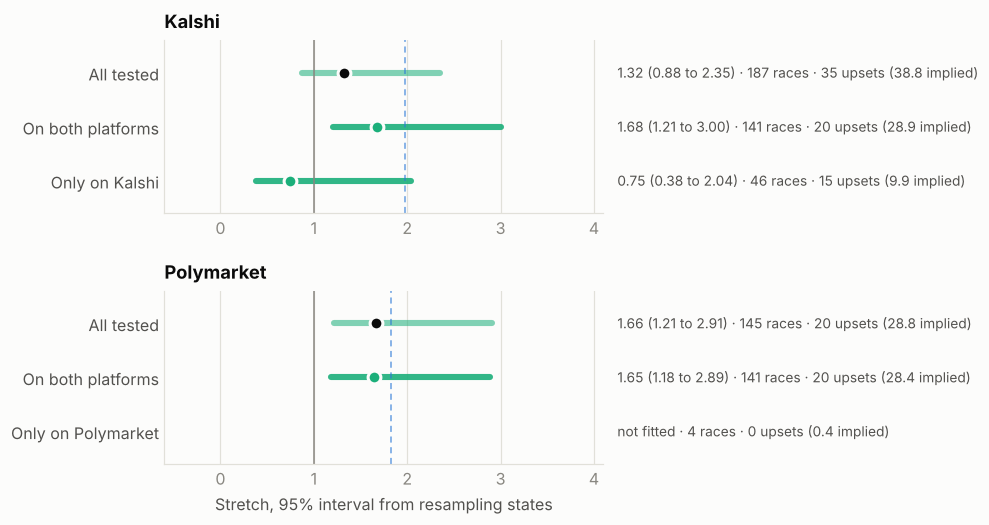

In [3]:
shared = set(test["Kalshi"]["race"]) & set(test["Polymarket"]["race"])
split_rows = []
for p in PLATFORMS:
    t = test[p]
    for name, part in (("All tested", t), ("On both platforms", t[t["race"].isin(shared)]),
                       (f"Only on {p}", t[~t["race"].isin(shared)])):
        part = part.reset_index(drop=True)
        row = {"platform": p, "group": name, "contests": len(part), "states": part["state"].nunique(),
               "upsets": int((1 - part["won"]).sum()), "upsets implied": float((1 - part["price"]).sum())}
        if len(part) >= 5 and row["upsets"] > 0:
            row["stretch"] = stretch.fit(part["log_odds"], part["won"])
            row["low"], row["high"] = stretch.interval(stretch.bootstrap(part, "state")["All"])
        split_rows.append(row)
split = pd.DataFrame(split_rows)
split.to_csv(TABLES / f"res_same_races_{STAGE}.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(10.5, 5.0))
cut = lambda v: float(np.clip(v, -0.5, 4.0))
for ax, p in zip(axes, PLATFORMS):
    part = split[split["platform"] == p].reset_index(drop=True)
    for y, (_, row) in zip(range(len(part) - 1, -1, -1), part.iterrows()):
        label = f"{row['contests']} races · {row['upsets']} upsets ({row['upsets implied']:.1f} implied)"
        if pd.notna(row.get("stretch")):
            ax.plot([cut(row["low"]), cut(row["high"])], [y, y], color=MIDTERMS, linewidth=4, solid_capstyle="round",
                    alpha=0.9 if row["group"] != "All tested" else 0.55)
            if row["high"] > 4:
                ax.scatter([4.0], [y], marker=">", s=40, color=MIDTERMS, linewidth=0)
            ax.scatter([cut(row["stretch"])], [y], s=70, color=MIDTERMS if row["group"] != "All tested" else INK,
                       zorder=3, edgecolor=SURFACE, linewidth=2)
            label = f"{show(row['stretch'])} ({show(row['low'])} to {show(row['high'])}) · " + label
        else:
            label = "not fitted · " + label
        ax.text(4.25, y, label, va="center", fontsize=9, color=INK_2)
    ax.axvline(1, color=MUTED, linewidth=1)
    ax.axvline(midterm_test.BASELINE_B[p], color=GENERAL, linewidth=1, linestyle=(0, (4, 3)), alpha=0.7)
    ax.set_yticks(range(len(part)), part["group"][::-1])
    ax.set_xlim(-0.6, 4.1)
    ax.set_ylim(-0.6, len(part) - 0.4)
    ax.set_title(p, pad=8)
    value_grid(ax, "x")
axes[1].set_xlabel("Stretch, 95% interval from resampling states")
fig.subplots_adjust(left=0.17, right=0.55, hspace=0.45)
save(fig, "res_same_races")
split.round(2)

## 3. Where the upsets fell

For each state, the number of midterm upsets minus the number the prices implied (the sum of one minus the favourite's
price). Blue: fewer upsets than priced, so favourites were underpriced there. Orange: more upsets than priced. Each tile
shows the actual and the implied number of upsets.

/tmp/ipykernel_577/1519391788.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.06, 1, 1), h_pad=2)


contests  upsets  implied   gap
           state                                 
Kalshi     MO            3       2     1.20  0.80
           SC            4       2     0.90  1.10
Polymarket SC            3       2     0.86  1.14
Kalshi     OH           13       5     3.51  1.49
Polymarket TX           16       5     3.23  1.77
Kalshi     NC            7       4     1.52  2.48
Polymarket NC            7       4     1.48  2.52
Kalshi     TX           26      12     5.04  6.96

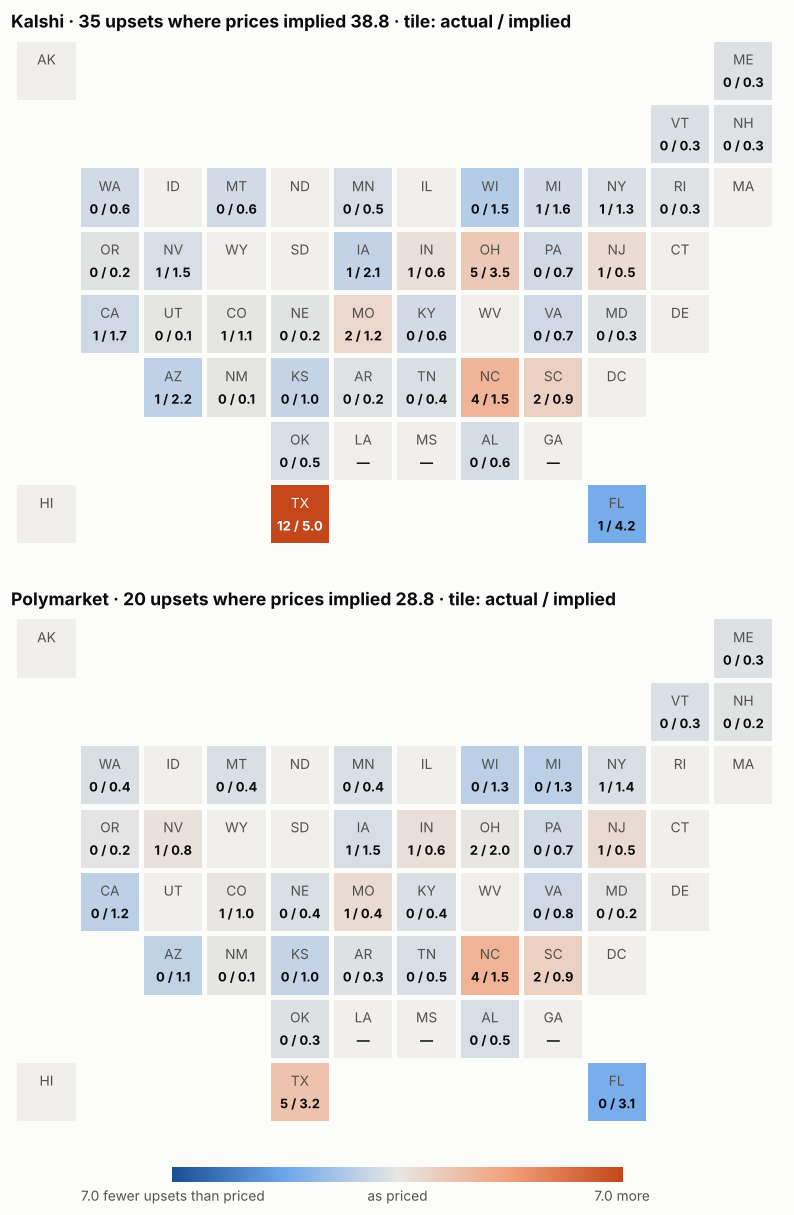

In [4]:
TILES = {
    "AK": (0, 0), "ME": (11, 0), "VT": (10, 1), "NH": (11, 1),
    "WA": (1, 2), "ID": (2, 2), "MT": (3, 2), "ND": (4, 2), "MN": (5, 2), "IL": (6, 2), "WI": (7, 2),
    "MI": (8, 2), "NY": (9, 2), "RI": (10, 2), "MA": (11, 2),
    "OR": (1, 3), "NV": (2, 3), "WY": (3, 3), "SD": (4, 3), "IA": (5, 3), "IN": (6, 3), "OH": (7, 3),
    "PA": (8, 3), "NJ": (9, 3), "CT": (10, 3),
    "CA": (1, 4), "UT": (2, 4), "CO": (3, 4), "NE": (4, 4), "MO": (5, 4), "KY": (6, 4), "WV": (7, 4),
    "VA": (8, 4), "MD": (9, 4), "DE": (10, 4),
    "AZ": (2, 5), "NM": (3, 5), "KS": (4, 5), "AR": (5, 5), "TN": (6, 5), "NC": (7, 5), "SC": (8, 5),
    "DC": (9, 5),
    "OK": (4, 6), "LA": (5, 6), "MS": (6, 6), "AL": (7, 6), "GA": (8, 6),
    "HI": (0, 7), "TX": (4, 7), "FL": (9, 7),
}
by_state = {p: test[p].groupby("state").agg(contests=("won", "size"), upsets=("won", lambda w: int((1 - w).sum())),
                                             implied=("price", lambda q: float((1 - q).sum())))
            for p in PLATFORMS}
extent = max(float((g["upsets"] - g["implied"]).abs().max()) for g in by_state.values())

fig, axes = plt.subplots(2, 1, figsize=(8.2, 11.2))
for ax, p in zip(axes, PLATFORMS):
    g = by_state[p]
    for state, (col, row) in TILES.items():
        if state in g.index:
            gap = g.loc[state, "upsets"] - g.loc[state, "implied"]
            shade = DIVERGING(0.5 + gap / (2 * extent))
            dark = abs(gap) / extent > 0.55
            text = f"{int(g.loc[state, 'upsets'])} / {g.loc[state, 'implied']:.1f}"
        else:
            shade, dark = EMPTY_TILE, False
            text = "—" if state in midterm_test.RUNOFF_STATES else ""
        ax.add_patch(plt.Rectangle((col, -row), 0.92, 0.92, color=shade, linewidth=0))
        ax.text(col + 0.46, -row + 0.64, state, ha="center", va="center", fontsize=9, color="white" if dark else INK_2)
        ax.text(col + 0.46, -row + 0.28, text, ha="center", va="center", fontsize=8.5, weight="bold",
                color="white" if dark else INK)
    total, implied = int(g["upsets"].sum()), g["implied"].sum()
    ax.set_title(f"{p} · {total} upsets where prices implied {implied:.1f} · tile: actual / implied", fontsize=11.5)
    ax.set_xlim(-0.1, 12.1); ax.set_ylim(-7.2, 1.0); ax.set_aspect("equal"); ax.axis("off")
key = fig.add_axes([0.25, 0.035, 0.5, 0.012])
key.imshow(np.linspace(0, 1, 256)[None, :], aspect="auto", cmap=DIVERGING)
key.set_yticks([])
key.set_xticks([0, 127.5, 255], [f"{extent:.1f} fewer upsets than priced", "as priced", f"{extent:.1f} more"])
key.tick_params(length=0, labelsize=9, colors=INK_2)
for side in key.spines.values():
    side.set_visible(False)
fig.tight_layout(rect=(0, 0.06, 1, 1), h_pad=2)
save(fig, "res_upsets_map")
pd.concat({p: g for p, g in by_state.items()}).assign(gap=lambda d: d["upsets"] - d["implied"]).sort_values("gap").round(2).tail(8)

## 4. Checks on the training primaries

Kalshi's training primaries are strongly overconfident. Two checks: are the upsets concentrated in states where a later
runoff can decide the nomination, and in markets that settled long after the first vote? Intervals resample election
days.

**A note on the fit.** `stretch.fit` uses Newton's method from b = 1, clipped at ±50. When the best stretch is negative
(more favourites lost than won, at the prices), Newton can overshoot and stop at +50 instead. That happens on some
resamples of a few primary days, and it would put this section's upper ends at 50. Here the stretch is found by
bisection on the slope of the log-likelihood, which always lands on the true maximum; on the full samples it gives the
same values as `stretch.fit`. The frozen code is left unchanged, and the difference is disclosed in the paper.

,platform,group,contests,election days,upsets,upsets implied,stretch,low,high
0,Kalshi,All primaries,78,21,31,13.84,0.32,0.02,0.69
1,Kalshi,Runoff states,31,6,15,6.69,0.16,-0.19,1.10
2,Kalshi,Other states,47,16,16,7.15,0.40,0.03,0.83
3,Kalshi,Settled within 14 days,74,19,29,13.34,0.33,-0.01,0.72
4,Polymarket,All primaries,23,17,6,3.75,0.88,0.41,1.66
5,Polymarket,Runoff states,5,4,1,0.72,1.02,-0.38,inf
6,Polymarket,Other states,18,13,5,3.02,0.84,0.29,1.84
7,Polymarket,Settled within 14 days,18,13,5,2.89,0.81,0.27,1.68


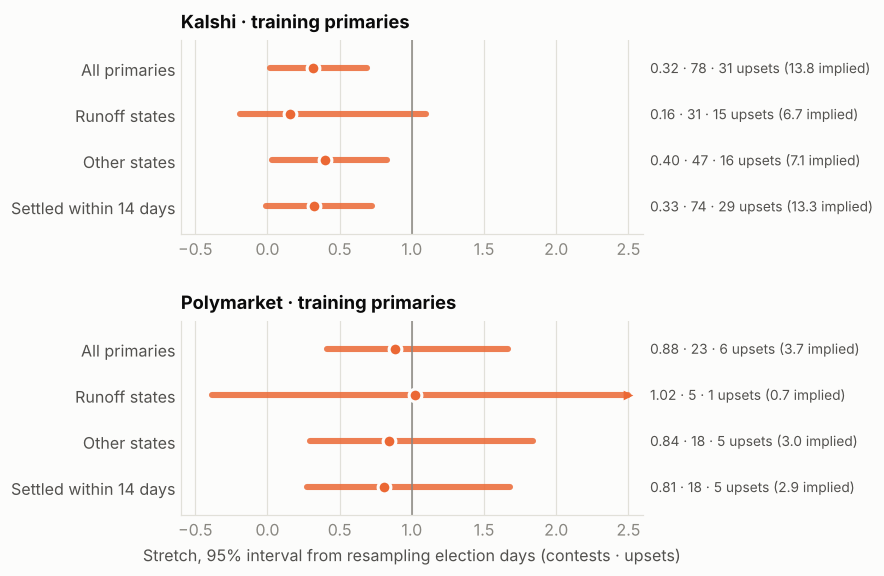

In [5]:
def fit_by_bisection(log_odds, won, b_max=50.0):
    """The same maximum-likelihood stretch as stretch.fit, found by bisection: the log-likelihood is concave in b,
    so its slope falls as b rises and crosses zero once."""
    x, y = np.asarray(log_odds, float), np.asarray(won, float)
    if len(x) == 0:
        return np.nan
    x, y = x[x != 0], y[x != 0]
    if np.all(y == 1):
        return np.inf
    if np.all(y == 0):
        return -np.inf
    slope = lambda b: np.sum(x * (y - 1 / (1 + np.exp(-b * x))))
    low, high = -b_max, b_max
    if slope(low) <= 0:
        return low
    if slope(high) >= 0:
        return high
    for _ in range(100):
        middle = (low + high) / 2
        low, high = (middle, high) if slope(middle) > 0 else (low, middle)
    return (low + high) / 2


def bootstrap_by_bisection(df, by):
    """stretch.bootstrap with the same seed and resamples, refitting by bisection."""
    newton, stretch.fit = stretch.fit, fit_by_bisection
    try:
        return stretch.bootstrap(df, by)
    finally:
        stretch.fit = newton


RUNOFF_PRIMARY = {"TX", "GA", "NC", "MS", "OK", "AR", "AL", "SD", "LA"}   # states where a primary can go to a runoff
calendar = pd.read_csv("../calendar_and_prices/contest_calendar.csv", dtype={"contest_id": str}).set_index(["platform", "contest_id"])
check_rows = []
for p in PLATFORMS:
    d = stretch.load(p)
    pr = d[(d["kind"] == "Primary") & (d["election_key"] != midterm_test.TEST_DAY)].copy()
    resolved = calendar.reindex(list(zip(pr["platform"], pr["contest_id"])))["market_resolved"].to_numpy()
    pr["days_to_settle"] = (pd.Series(pd.to_datetime(resolved), index=pr.index)
                            - pd.to_datetime(pr["election_key"].str[3:])).dt.days
    for name, part in (("All primaries", pr), ("Runoff states", pr[pr["state"].isin(RUNOFF_PRIMARY)]),
                       ("Other states", pr[~pr["state"].isin(RUNOFF_PRIMARY)]),
                       ("Settled within 14 days", pr[pr["days_to_settle"] <= 14])):
        part = part.reset_index(drop=True)
        row = {"platform": p, "group": name, "contests": len(part), "election days": part["election_key"].nunique(),
               "upsets": int((1 - part["won"]).sum()), "upsets implied": float((1 - part["price"]).sum())}
        if len(part) >= 5:
            row["stretch"] = fit_by_bisection(part["log_odds"], part["won"])
            assert np.isclose(row["stretch"], stretch.fit(part["log_odds"], part["won"]))
            row["low"], row["high"] = (stretch.interval(bootstrap_by_bisection(part, "day")["All"])
                                       if part["election_key"].nunique() > 2 else (np.nan, np.nan))
        check_rows.append(row)
checks = pd.DataFrame(check_rows)
checks.to_csv(TABLES / f"res_primary_checks_{STAGE}.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(10.5, 5.6))
cut = lambda v: float(np.clip(v, -0.5, 2.5))
for ax, p in zip(axes, PLATFORMS):
    part = checks[checks["platform"] == p].reset_index(drop=True)
    for y, (_, row) in zip(range(len(part) - 1, -1, -1), part.iterrows()):
        label = f"{row['contests']} · {row['upsets']} upsets ({row['upsets implied']:.1f} implied)"
        if pd.notna(row.get("stretch")):
            if pd.notna(row.get("low")):
                ax.plot([cut(row["low"]), cut(row["high"])], [y, y], color=PRIMARY, linewidth=4, solid_capstyle="round", alpha=0.85)
                if row["high"] > 2.5:
                    ax.scatter([2.5], [y], marker=">", s=40, color=PRIMARY, linewidth=0)
                if row["low"] < -0.5:
                    ax.scatter([-0.5], [y], marker="<", s=40, color=PRIMARY, linewidth=0)
            ax.scatter([cut(row["stretch"])], [y], s=70, color=PRIMARY, zorder=3, edgecolor=SURFACE, linewidth=2)
            label = f"{row['stretch']:.2f} · " + label
        ax.text(2.65, y, label, va="center", fontsize=9, color=INK_2)
    ax.axvline(1, color=MUTED, linewidth=1)
    ax.set_yticks(range(len(part)), part["group"][::-1])
    ax.set_xlim(-0.6, 2.6)
    ax.set_ylim(-0.6, len(part) - 0.4)
    ax.set_title(f"{p} · training primaries", pad=8)
    value_grid(ax, "x")
axes[1].set_xlabel("Stretch, 95% interval from resampling election days (contests · upsets)")
fig.subplots_adjust(left=0.2, right=0.6, hspace=0.45)
save(fig, "res_primary_checks")
checks.round(2)

## 5. p-values

**Level:** is the midterm stretch different from 1? **Persistence:** does a stretch fixed before the vote make the
midterm results more likely than the raw prices do? Each is computed naively (contests independent) and allowing for
contests in one state moving together. These are exploratory; the pre-registered test reads only the interval.

In [6]:
norm_sf = lambda z: 0.5 * math.erfc(z / math.sqrt(2))
chi1_sf = lambda x: math.erfc(math.sqrt(x / 2))


def loglik(x, y, b):
    chance = 1 / (1 + np.exp(-b * x))
    return np.log(np.where(y == 1, chance, 1 - chance))


p_rows = []
for p in PLATFORMS:
    t = test[p]
    x, y, st = t["log_odds"].to_numpy(), t["won"].to_numpy(), t["state"].to_numpy()
    groups = [np.flatnonzero(st == s) for s in np.unique(st)]
    G = len(groups)
    b = stretch.fit(x, y)
    lr = 2 * (loglik(x, y, b).sum() - loglik(x, y, 1.0).sum())
    chance = 1 / (1 + np.exp(-b * x))
    score, H = x * (y - chance), np.sum(x * x * chance * (1 - chance))
    se_state = math.sqrt(sum(score[g].sum() ** 2 for g in groups) * G / (G - 1)) / H
    share_below = 1 - resamples.set_index("platform").loc[p, "share above 1"]
    p_rows.append({"platform": p, "question": "level: stretch above 1", "naive p": chi1_sf(lr) / 2,
                   "p allowing for states": norm_sf((b - 1) / se_state), "resamples at or below 1": share_below})
    earlier = stretch.load(p)
    earlier = earlier[(earlier["kind"] == "General") & (earlier["election_key"] != midterm_test.TEST_DAY)]
    for name, b0 in (("frozen 2024 value", midterm_test.BASELINE_B[p]),
                     ("earlier general elections", stretch.fit(earlier["log_odds"], earlier["won"]))):
        gain = loglik(x, y, b0) - loglik(x, y, 1.0)
        S = np.array([gain[g].sum() for g in groups])
        se = math.sqrt(G / (G - 1) * np.sum((S - S.mean()) ** 2))
        p_rows.append({"platform": p, "question": f"persistence: {name} ({b0:.2f})",
                       "times as likely as raw prices": math.exp(gain.sum()),
                       "naive p": norm_sf(gain.mean() / (gain.std(ddof=1) / math.sqrt(len(gain)))),
                       "p allowing for states": norm_sf(S.sum() / se)})
pvalues = pd.DataFrame(p_rows)
pvalues.to_csv(TABLES / f"res_pvalues_{STAGE}.csv", index=False)
pvalues.round(4)

,platform,question,naive p,p allowing for states,resamples at or below 1,times as likely as raw prices
0,Kalshi,level: stretch above 1,0.0241,0.1532,0.079,NaN
1,Kalshi,persistence: frozen 2024 value (1.97),0.7500,0.6217,NaN,0.0447
2,Kalshi,persistence: earlier general elections (1.28),0.0728,0.2352,NaN,6.8465
3,Polymarket,level: stretch above 1,0.0010,0.0220,0.002,NaN
4,Polymarket,persistence: frozen 2024 value (1.83),0.0440,0.1328,NaN,98.6092
5,Polymarket,persistence: earlier general elections (1.61),0.0083,0.0621,NaN,115.4985
